# From pandas to scikit-learn: predict the price of a listing with a straight line

In the pandas block you read, cleaned and summarised the Berlin listings. Here the same table feeds your first **machine learning model**: a linear regression that predicts the price per night from the number of guests, and a score of how good it is. After this notebook you can read a file with pandas, clean it with Boolean masks, fit `LinearRegression` from scikit-learn and measure it with R².

## Overview

| Section | What it covers |
|---|---|
| 1 The problem | what we predict, from what, and the line $\text{price} = a \cdot \text{num\_of\_guests} + b$ |
| 2 Load the data | `pd.read_parquet`, selecting columns with `[[...]]`, `rename`, a table that explains them |
| 3 Look at the data | `describe`, missing values, histograms of two columns, price against guests |
| 4 Clean the data | three Boolean masks, each with its reason, and the effect on the prices and on the relationship |
| 5 Split the data | training listings and test listings |
| 6 Fit the line | `LinearRegression`, `fit`, slope and intercept |
| 7 Measure the line with R² | `predict`, R², the average error in euros, a picture |
| 8 Your turn | a second feature, `bedrooms` |

In [1]:
# Run the code from the repository root, where the case-study paths start.
import os
from pathlib import Path

os.chdir(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "case-study").is_dir()))

The next cell imports what the notebook needs. `pandas` and `numpy` and `matplotlib` you know from the previous blocks; the two new names come from scikit-learn: `train_test_split` cuts a table into two parts, `LinearRegression` is the model, and `r2_score` and `mean_absolute_error` measure it.

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression  # the model: ordinary least squares
from sklearn.metrics import mean_absolute_error, r2_score  # the two scores
from sklearn.model_selection import train_test_split  # cuts a table into training and test part

## 1 The problem

A host asks: *what price per night should I ask for my flat?* Part of the answer is size: a flat for six guests costs more than a room for one. We test how far **one number**, the number of guests, takes us.

A straight line has two numbers, a slope $a$ and an intercept $b$:

$$\text{price} = a \cdot \text{num\_of\_guests} + b$$

Read aloud: the price is $a$ euros for every guest the listing sleeps, plus a starting amount $b$. **Fitting** the model means letting the computer find the $a$ and $b$ that put the line closest to the real listings.

## 2 Load the data

`pd.read_parquet(path)` reads a Parquet file into a DataFrame. We read the **whole file**, every column, and then **select** the columns we need with pandas:

- `table["price"]` (single brackets, one name) returns one column as a Series.
- `table[["price", "accommodates"]]` (double brackets, a list of names) returns a **DataFrame** with just those columns, in that order.
- `table.rename(columns={"old_name": "new_name"})` returns a new DataFrame with the column renamed. The file calls the number of guests `accommodates`; we rename it to `num_of_guests`, a name that says what it is.

In [3]:
# read_parquet returns a DataFrame with every column of the file
airbnb_listings = pd.read_parquet("case-study/airbnb/data/listings.parquet")

# shape is (number of rows, number of columns): the file has one row per listing and many columns
print(airbnb_listings.shape)

# Select the three columns we need: a list of names inside the brackets gives a DataFrame (the file's name for the guests is accommodates)
selected_columns = airbnb_listings[["accommodates", "price", "minimum_nights"]]

# rename(columns={old: new}) returns a new table in which accommodates is called num_of_guests
listings = selected_columns.rename(columns={"accommodates": "num_of_guests"})

print(listings.shape)

# a first look at the table: the first five rows
listings.head()

(10221, 42)
(10221, 3)


,num_of_guests,price,minimum_nights
0,2,160.71,2.0
1,7,193.33,6.0
2,1,NaN,180.0
3,2,10.88,93.0
4,4,372.67,3.0


One row is one Airbnb listing in Berlin. The three columns we selected:

| Column | Meaning | Unit or values |
|---|---|---|
| `price` | the **target** `y`: what the host asks per night | euros, a number; empty when the host showed no price |
| `num_of_guests` | the **feature** `x`: how many guests the listing sleeps (called `accommodates` in the file) | whole number, 1 to 16 |
| `minimum_nights` | the fewest nights a guest must book | nights; 28 or more means a monthly rental |

## 3 Look at the data

Before modelling, look at every column you will use. `listings.describe()` summarises each numeric column: count of non-empty values, mean, standard deviation, minimum, quartiles and maximum. `listings.isna().sum()` counts the empty (missing) values per column.

In [4]:
# describe() summarises each numeric column; the "count" row shows how many values are not missing
print(listings.describe())

# isna() is True where a value is missing; sum() counts the True values per column
print(listings.isna().sum())

       num_of_guests         price  minimum_nights
count   10221.000000   6754.000000    10219.000000
mean        3.128559    161.038836       34.631275
std         1.982385    219.834642       52.540043
min         1.000000      2.720000        1.000000
25%         2.000000     70.067500        1.000000
50%         2.000000    130.000000        3.000000
75%         4.000000    205.500000       92.000000
max        16.000000  10025.000000     1125.000000
num_of_guests        0
price             3467
minimum_nights       2
dtype: int64


Numbers hide shape, so draw the two columns that look odd. A histogram counts the listings per range of values. The minimum stay is drawn on a normal scale with one bar per night (`np.arange(0.5, 121, 1)` makes the bin edges 0.5, 1.5, 2.5, … 120.5, halfway between whole nights, so each bar holds exactly one night); `clip(upper=120)` moves every stay of more than 120 nights into the last bar. The prices stretch from a few euros to thousands, so that x-axis uses a **log scale** (`ax.set_xscale("log")`: each step to the right multiplies the value by ten instead of adding), with bin edges from `np.logspace(start, stop, n)`, which grow by a constant factor. The dashed lines mark cuts we discuss in the next section.

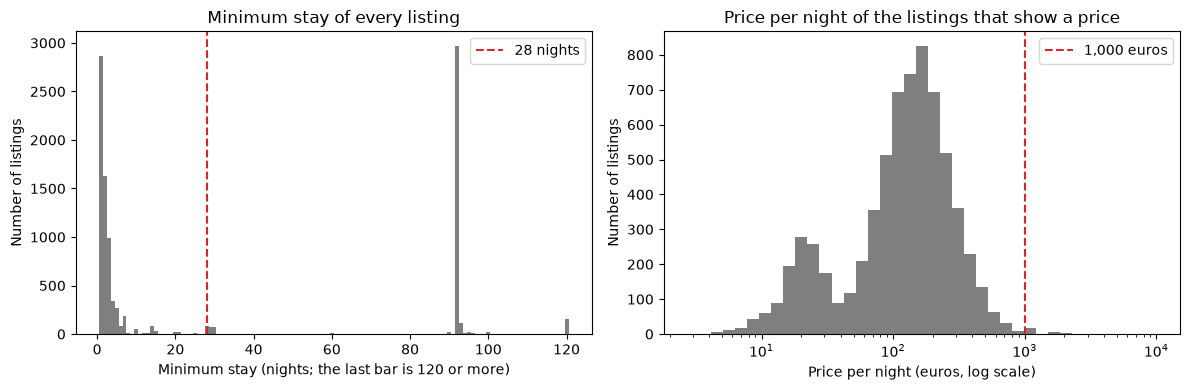

In [5]:
fig, (ax_nights, ax_price) = plt.subplots(1, 2, figsize=(12, 4))

# Left: the minimum stay on a normal scale, one bar per night.
# Stays longer than 120 nights are drawn in the last bar (clip), so a few very long stays
# (up to 1,125 nights) do not stretch the axis and squash everything else.
longest_stay_shown = 120
nights_shown = listings["minimum_nights"].dropna().clip(upper=longest_stay_shown)

# One bar per whole night means the bar edges lie halfway between nights: 0.5, 1.5, 2.5, ... 120.5.
# arange(start, stop, step) counts up from start and never reaches stop, so stop = 121 ends at 120.5.
night_bins = np.arange(0.5, longest_stay_shown + 1, 1)
ax_nights.hist(nights_shown, bins=night_bins, color="tab:gray")
# axvline draws a vertical line at x = 28; "--" makes it dashed, label= feeds the legend
ax_nights.axvline(28, color="tab:red", linestyle="--", label="28 nights")
ax_nights.set_title("Minimum stay of every listing")
ax_nights.set_xlabel("Minimum stay (nights; the last bar is 120 or more)")
ax_nights.set_ylabel("Number of listings")
ax_nights.legend()

# Right: the price. dropna() removes the missing prices, which hist cannot draw
priced = listings["price"].dropna()
price_bins = np.logspace(np.log10(priced.min()), np.log10(priced.max()), 40)
ax_price.hist(priced, bins=price_bins, color="tab:gray")
# axvline draws a vertical line at x = 1000; "--" makes it dashed, label= feeds the legend
ax_price.axvline(1000, color="tab:red", linestyle="--", label="1,000 euros")
ax_price.set_xscale("log")
ax_price.set_title("Price per night of the listings that show a price")
ax_price.set_xlabel("Price per night (euros, log scale)")
ax_price.set_ylabel("Number of listings")
ax_price.legend()

plt.tight_layout()
plt.show()

**What do you see?** The minimum stay has two crowds: many listings need only one to three nights, and a second group sits far to the right, with a tall bar at about three months. The prices have a main crowd around 150 euros, a smaller bump near 20 euros that looks odd for a night in Berlin, and a thin tail that runs out to several thousand euros.

Now the relationship we want to model: price against the number of guests, one dot per listing.

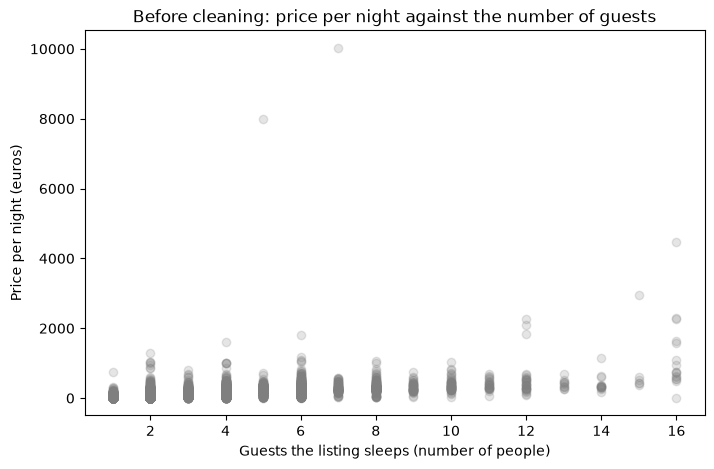

In [6]:
fig, ax = plt.subplots(figsize=(8, 5))

# Each dot is one listing with a price: the guests it sleeps and the price it asks
ax.scatter(listings["num_of_guests"], listings["price"], alpha=0.2, color="tab:gray")
ax.set_title("Before cleaning: price per night against the number of guests")
ax.set_xlabel("Guests the listing sleeps (number of people)")
ax.set_ylabel("Price per night (euros)")
plt.show()

**What do you see?** Prices rise with the number of guests, but the few dots near the top of the plot, at several thousand euros, stretch the whole axis and make the bulk of the listings look flat. A line fitted to this plot would chase them. The next section removes them on purpose.

## 4 Clean the data

A model learns whatever the table shows, so odd rows give an odd line. The plots above point to three groups of rows to leave out. Each rule is a **Boolean mask**, a column of `True`/`False` with one value per row, that says which rows to keep. `listings[mask]` keeps the rows where the mask is `True`; `mask_1 & mask_2` is `True` where both are.

### Rule 1 · Keep listings that show a price

The model learns from prices, so a listing without one gives it nothing. `notna()` is `True` where a value is **not** missing.

In [7]:
# True where the host showed a price
has_price = listings["price"].notna()

# sum() counts the True values; the opposite (~ flips True and False) counts the listings without price
print("listings with a price:   ", has_price.sum())
print("listings without a price:", (~has_price).sum())

listings with a price:    6754
listings without a price: 3467


### Rule 2 · Keep short stays

A listing with a minimum stay of **28 nights or more** is a monthly rental: the host rents it for months, not for a night. The price column is still called "per night", but these prices live in another market. Look at row 3 of the first look above: 10.88 euros at a minimum stay of 93 nights. We want the price of a night in a short stay, so we keep `minimum_nights < 28`. The next cell checks that the two groups really differ. It builds one mask for each group, keeps the rows with a price and that mask, takes their `price` column and computes the **median**, the middle price of the group (half of the listings cost less, half more).

In [8]:
# True where the minimum stay is below 28 nights (a short stay)
is_short_stay = listings["minimum_nights"] < 28

# True where the minimum stay is 28 nights or more (a monthly rental)
is_monthly_rental = listings["minimum_nights"] >= 28

# Rows to keep: the price is shown (has_price) AND the mask of the group is True.
# [...]["price"] then takes the price column of those rows.
short_stay_prices = listings[has_price & is_short_stay]["price"]
monthly_rental_prices = listings[has_price & is_monthly_rental]["price"]

# median() is the middle price of each group
print("median price per night, short stays:    ", short_stay_prices.median())
print("median price per night, monthly rentals:", monthly_rental_prices.median())

median price per night, short stays:     157.5
median price per night, monthly rentals: 23.01


### Rule 3 · Keep plausible prices

The third plot above showed a thin tail of very high prices. A model fitted by least squares **squares** every miss, so one listing at 10,000 euros counts as much as a hundred listings that miss by 1,000 euros: a few extreme prices pull the whole line upwards. We cap the price at **1,000 euros per night**. This is a judgement call, not a law: 500 or 2,000 would also be defensible, and a data scientist writes the choice down so that others can question it. The next cell counts the listings above the cap.

In [9]:
# True where the price is at most 1,000 euros per night (a missing price gives False)
has_plausible_price = listings["price"] <= 1000

# Count the listings with a price that the cap removes, and show how high the highest one is
n_above_cap = (has_price & ~has_plausible_price).sum()
print("listings priced above 1,000 euros:", n_above_cap)
print("highest price (euros):            ", listings["price"].max())

listings priced above 1,000 euros: 25
highest price (euros):             10025.0


### Apply the three rules

The operator `&` combines masks: a row stays only if all of them are `True`. The cell prints how many listings are left after each rule in turn.

In [10]:
# & combines masks: a row is kept only if all masks are True
clean_listings = listings[has_price & is_short_stay & has_plausible_price]

# How many rows survive after each rule, applied one after the other
print("all listings:                        ", len(listings))
print("after rule 1 (has a price):          ", len(listings[has_price]))
print("after rule 2 (and short stay):       ", len(listings[has_price & is_short_stay]))
print("after rule 3 (and plausible price):  ", len(clean_listings))

all listings:                         10221
after rule 1 (has a price):           6754
after rule 2 (and short stay):        5302
after rule 3 (and plausible price):   5278


The next cell shows the effect on the price. Both histograms use **the same bins on the same log axis**, so the bars can be compared one to one: grey is every listing with a price, green is what is left after the three rules.

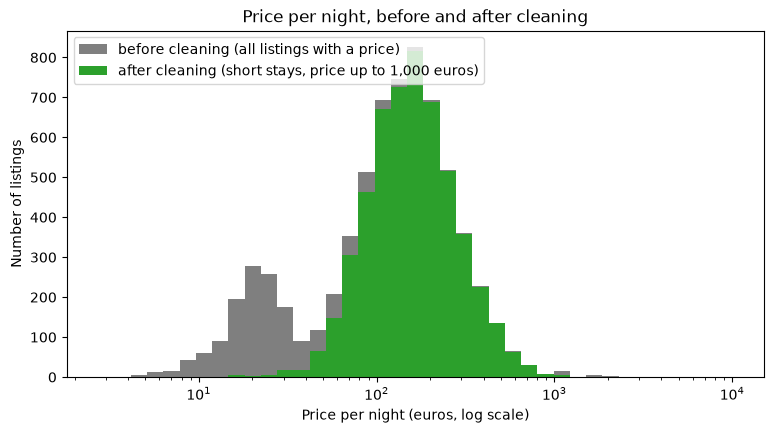

In [11]:
fig, ax = plt.subplots(figsize=(9, 4.5))

# The two sets of prices to compare: all prices shown, and the prices of the clean listings
prices_before_cleaning = listings["price"].dropna()  # dropna() removes missing prices; hist cannot draw them
prices_after_cleaning = clean_listings["price"]

# The same bins for both histograms, so the bars can be compared one to one (log scale)
price_bins = np.logspace(np.log10(prices_before_cleaning.min()), np.log10(prices_before_cleaning.max()), 40)

# Grey: before cleaning; green drawn on top: after cleaning
ax.hist(prices_before_cleaning, bins=price_bins, color="tab:gray", label="before cleaning (all listings with a price)")
ax.hist(prices_after_cleaning, bins=price_bins, color="tab:green", label="after cleaning (short stays, price up to 1,000 euros)")

ax.set_xscale("log")
ax.set_title("Price per night, before and after cleaning")
ax.set_xlabel("Price per night (euros, log scale)")
ax.set_ylabel("Number of listings")
ax.legend(loc="upper left")  # top left, where no bars are
plt.show()

**What do you see?** The grey bump near 20 euros is gone from the green bars: it was the monthly rentals. The tail beyond 1,000 euros is cut off, and the main crowd around 150 euros is untouched.

The relationship again, now on the clean listings. On the right, `groupby("num_of_guests")["price"].mean()` computes the **average price for each number of guests**, which is the pattern a line tries to capture.

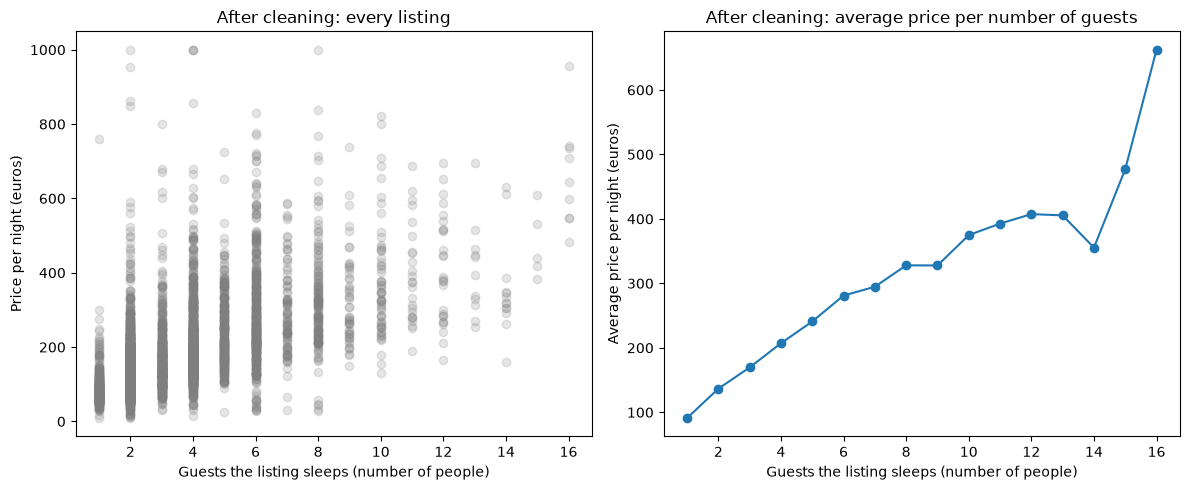

In [12]:
fig, (ax_dots, ax_means) = plt.subplots(1, 2, figsize=(12, 5))

# Left: one dot per clean listing
ax_dots.scatter(clean_listings["num_of_guests"], clean_listings["price"], alpha=0.2, color="tab:gray")
ax_dots.set_title("After cleaning: every listing")
ax_dots.set_xlabel("Guests the listing sleeps (number of people)")
ax_dots.set_ylabel("Price per night (euros)")

# Right: group the listings by the number of guests and average the price inside each group
mean_price_by_guests = clean_listings.groupby("num_of_guests")["price"].mean()
ax_means.plot(mean_price_by_guests.index, mean_price_by_guests.to_list(), marker="o", color="tab:blue")
ax_means.set_title("After cleaning: average price per number of guests")
ax_means.set_xlabel("Guests the listing sleeps (number of people)")
ax_means.set_ylabel("Average price per night (euros)")

plt.tight_layout()
plt.show()

**What do you see?** On the left the cloud now fills the plot and still rises. On the right the averages climb in a roughly straight path up to about twelve guests; beyond that few listings remain, so the averages jump around. The straight climb is why a line is a reasonable first model. The wide spread of the dots on the left, at every number of guests, already tells us the line will leave much of the price unexplained.

## 5 Split the data

If we score the line on the same listings it learned from, the score flatters it: it has seen these answers. So we hold some listings back. `train_test_split(X, y, test_size=0.2, random_state=0)` shuffles the rows and cuts them into a **training part** (80 %, to fit the line) and a **test part** (20 %, to score it). `random_state=0` fixes the shuffle, so everyone gets the same split.

scikit-learn names the inputs by convention: a capital `X` for the **table of features** (two-dimensional, even with one column, hence the double brackets `[["num_of_guests"]]`) and a small `y` for the **target** (one column).

In [13]:
# X is a table with one column (double brackets keep it a DataFrame); y is the price column
X = clean_listings[["num_of_guests"]]
y = clean_listings["price"]

# The function returns four pieces in this fixed order; test_size=0.2 holds back 20 % of the rows
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

print("training listings:", len(X_train))
print("test listings:    ", len(X_test))

training listings: 4222
test listings:     1056


## 6 Fit the line

`LinearRegression()` creates the model with its default settings; there is nothing to tune. `model.fit(X_train, y_train)` finds the slope and the intercept that minimise the squared distances between the line and the training prices. After fitting, the numbers are stored in `model.coef_` (one slope per feature) and `model.intercept_`.

**Predict.** Before running the cell: roughly how many euros does one extra guest add to the price? Write down your guess.

In [14]:
# Create the model; no settings, so scikit-learn uses ordinary least squares
model = LinearRegression()

# fit() learns the slope and the intercept from the training listings
model.fit(X_train, y_train)

# coef_ is an array with one slope per feature; we have one feature, so take the first
slope = model.coef_[0]
intercept = model.intercept_

print(f"price = {slope:.2f} * num_of_guests + {intercept:.2f}")

price = 31.43 * num_of_guests + 74.84


Read the line: every extra guest adds the slope in euros, and the intercept is where the line starts. A listing for four guests costs `slope * 4 + intercept` on this line.

## 7 Measure the line with R²

`model.predict(X_test)` applies the line to the test listings and returns one predicted price per listing. We compare the predictions with the real prices of the same listings, which the model never saw.

Two scores answer two questions:

$$R^2 = 1 - \frac{\sum_i (y_i - \hat{y}_i)^2}{\sum_i (y_i - \bar{y})^2} \qquad\qquad \text{MAE} = \frac{1}{n} \sum_i |y_i - \hat{y}_i|$$

Read aloud: $R^2$ is the share of the variation in prices that the line explains. It is 1 for a perfect line and 0 for a line no better than always guessing the average price; it can even be negative. The mean absolute error (MAE) is the average miss in euros, easy to explain to a host.

**Predict.** Will one number, the guests, explain more or less than half of the variation in prices?

In [15]:
# predict() returns one predicted price per test listing
predicted_prices = model.predict(X_test)

# r2_score(true, predicted): the share of the price variation the line explains
r2 = r2_score(y_test, predicted_prices)

# mean_absolute_error(true, predicted): the average miss in euros
mae = mean_absolute_error(y_test, predicted_prices)

# R^2 is a share between 0 and 1; multiplying by 100 turns it into a percentage
print(f"R^2 on the test listings: {r2:.3f}")
print(f"  -> the line explains {r2 * 100:.0f} % of the differences in price between listings.")
print(f"     The other {100 - r2 * 100:.0f} % it cannot explain with the number of guests alone.")

print(f"Mean absolute error (MAE): {mae:.1f} euros")
print(f"  -> on average, the predicted price is {mae:.0f} euros away from the real price.")

R^2 on the test listings: 0.321
  -> the line explains 32 % of the differences in price between listings.
     The other 68 % it cannot explain with the number of guests alone.
Mean absolute error (MAE): 62.0 euros
  -> on average, the predicted price is 62 euros away from the real price.


The picture: the test listings as dots and the fitted line over them. Many listings share the same number of guests, so each column of dots is one `num_of_guests` value; `alpha=0.2` makes dots transparent so that crowded places look darker.

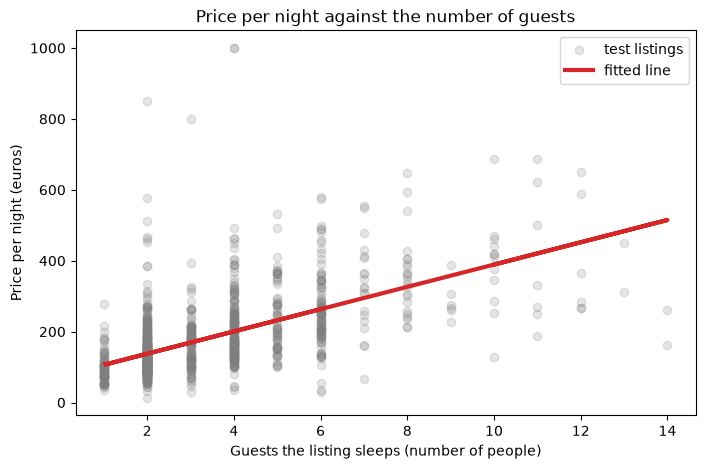

In [16]:
fig, ax = plt.subplots(figsize=(8, 5))

# Each dot is one test listing: the guests it sleeps and the price it asks
ax.scatter(X_test["num_of_guests"], y_test, alpha=0.2, color="tab:gray", label="test listings")

# Every predicted price lies on the fitted line, so plotting the predictions draws the line
ax.plot(X_test["num_of_guests"], predicted_prices, color="tab:red", linewidth=3, label="fitted line")

ax.set_title("Price per night against the number of guests")
ax.set_xlabel("Guests the listing sleeps (number of people)")
ax.set_ylabel("Price per night (euros)")
ax.legend()
plt.show()

**What do you see?** Where do the dots sit far from the line? Notice that the dots of one column spread over hundreds of euros: the number of guests alone cannot tell a cheap flat in Spandau from an expensive one in Mitte. That is the limit of a model with one feature, and the reason the next blocks add more columns.

**Finding.** A straight line through the number of guests predicts the price per night of a Berlin listing with an average miss of 62 euros, and it explains R² = 0.32, that is 32 % of the variation in prices, on 1,056 test listings it has not seen. Every extra guest adds about 31 euros. The limit is the single feature: listings with the same number of guests differ by hundreds of euros, so the line needs more columns, such as the district, to do better.

## 8 Your turn

> **Your turn.** Add the column `bedrooms` to the table and fit a line with two features, `X = clean_listings[["num_of_guests", "bedrooms"]]`. Some listings have no `bedrooms`: first remove them with a fourth mask. Does R² on the test listings go up?

*Hint:* add `"bedrooms"` to the list of selected columns in Section 2, build `has_bedrooms = listings["bedrooms"].notna()` and add it to the mask with `&`. The model needs no other change, because `coef_` then holds one slope per feature.

In [17]:
# Your turn

> **Note · Why not a more complex model?** It is tempting to replace the straight line with a curve (`PolynomialFeatures`), a random forest or gradient boosting. On this **one column** that barely changes R², for two reasons:
>
> 1. **The line already fits the pattern.** The average price per number of guests (Section 4) climbs in a nearly straight path, so a flexible model has nothing more to bend towards. With one feature, a random forest or gradient boosting can only predict the average price for each number of guests, which is almost what the line already does.
> 2. **The misses come from information the model never sees.** Listings with the same number of guests differ by hundreds of euros because of the district, the room type, the size and the quality of the flat. A more complex model can only use the columns it is given.
>
> The way to a better score is **more columns**, as in the *Your turn* above, not a more complex model on the same single column. More flexible models start to pay off once there are several features to combine.